# German → English Neural Machine Translation: Fixed Context vs. Concatenate Attention

**Reproducible lab submission notebook** — aligned to the faculty brief. It implements a packed-LSTM encoder–decoder baseline, additive/concatenate attention with a source-padding mask, greedy decoding, beam search, controlled training, perplexity/BLEU evaluation, examples, and attention maps.

> **Run order:** Runtime → Change runtime type → GPU; run all cells. The first dataset run requires internet. Full training can take substantial time. Results are generated by your run and are not pre-filled. A smoke test validates code paths only; it is not evidence of translation quality.

**Submission hygiene:** the notebook writes only plots/results/optional checkpoints into `seq2seq_attention_outputs/`. Do not include downloaded data or checkpoints when submitting unless requested. Record the actual configuration and whether the run completed.

In [1]:
# 0. Setup and reproducibility
%pip -q install datasets sacrebleu matplotlib

import os, re, math, random, json, time, copy, platform
from pathlib import Path
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from datasets import load_dataset
from sacrebleu.metrics import BLEU

SEED = 17
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Full-quality run settings. For a quick code-path check only, set DATA_MODE='smoke'
DATA_MODE = 'multi30k'          # 'multi30k' or 'smoke'
MAX_TRAIN_PAIRS = None          # None = all training pairs; otherwise seeded subset
RUN_FULL_TRAINING = True
EPOCHS = 12
PATIENCE = 3
BATCH_SIZE = 64
EMB_DIM = 128
HIDDEN_DIM = 256
LEARNING_RATE = 1e-3
TEACHER_FORCING_RATIO = 0.5
TEST_EVAL_LIMIT = None          # None = full test split; use e.g. 200 for a limited run
MAX_DECODE_STEPS = 40
BEAM_WIDTH = 3
LENGTH_ALPHA = 0.6
NUM_WORKERS = 2 if os.name != 'nt' else 0
OUTPUT_DIR = Path('seq2seq_attention_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))
print('Config:', {k:v for k,v in dict(DATA_MODE=DATA_MODE, MAX_TRAIN_PAIRS=MAX_TRAIN_PAIRS, RUN_FULL_TRAINING=RUN_FULL_TRAINING, EPOCHS=EPOCHS, BATCH_SIZE=BATCH_SIZE, EMB_DIM=EMB_DIM, HIDDEN_DIM=HIDDEN_DIM, TEST_EVAL_LIMIT=TEST_EVAL_LIMIT).items()})

Python: 3.13.16 | PyTorch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4
Config: {'DATA_MODE': 'multi30k', 'MAX_TRAIN_PAIRS': None, 'RUN_FULL_TRAINING': True, 'EPOCHS': 12, 'BATCH_SIZE': 64, 'EMB_DIM': 128, 'HIDDEN_DIM': 256, 'TEST_EVAL_LIMIT': None}


## 1. Data, splits, and vocabulary

Vocabulary is fitted on training text only. Source duplicates appearing in training are removed from validation/test and the retained evaluation sizes are reported. This changes evaluation set sizes and is documented. The tokenizer is a simple word/punctuation tokenizer, matching the pedagogical lab rather than a production subword system.

In [2]:
SMOKE_TRAIN = [
 ('das buch ist rot','the book is red'), ('das auto ist blau','the car is blue'),
 ('das haus ist grün','the house is green'), ('das boot ist gelb','the boat is yellow'),
 ('ein mann geht','a man walks'), ('eine frau geht','a woman walks'),
 ('ein mann läuft','a man runs'), ('eine frau läuft','a woman runs'),
 ('der hund ist klein','the dog is small'), ('die katze ist schwarz','the cat is black'),
 ('ein kind spielt','a child plays'), ('der mann liest ein buch','the man reads a book')]
SMOKE_VALID = [('das auto ist rot','the car is red'), ('die katze ist klein','the cat is small')]
SMOKE_TEST = [('das buch ist blau','the book is blue'), ('ein kind läuft','a child runs')]
def normalized(text): return ' '.join(text.lower().split())
def remove_seen_sources(pairs, seen):
    kept=[]
    for src,tgt in pairs:
        key=normalized(src)
        if key not in seen: kept.append((src,tgt)); seen.add(key)
    return kept

if DATA_MODE == 'smoke':
    train_pairs, valid_pairs, test_pairs = list(SMOKE_TRAIN), list(SMOKE_VALID), list(SMOKE_TEST)
elif DATA_MODE == 'multi30k':
    raw = load_dataset('bentrevett/multi30k')
    train_pairs = [(row['de'], row['en']) for row in raw['train']]
    random.Random(SEED).shuffle(train_pairs)
    if MAX_TRAIN_PAIRS is not None: train_pairs = train_pairs[:MAX_TRAIN_PAIRS]
    valid_pairs = [(row['de'], row['en']) for row in raw['validation']]
    test_pairs = [(row['de'], row['en']) for row in raw['test']]
    seen={normalized(s) for s,_ in train_pairs}
    valid_pairs=remove_seen_sources(valid_pairs,seen)
    test_pairs=remove_seen_sources(test_pairs,seen)
else: raise ValueError("DATA_MODE must be 'smoke' or 'multi30k'")
assert train_pairs and valid_pairs and test_pairs
print(f'train={len(train_pairs):,}, validation={len(valid_pairs):,}, test after source dedup={len(test_pairs):,}')
print('Training example:', train_pairs[0])

PAD, UNK, SOS, EOS = 0, 1, 2, 3
SPECIALS=['<pad>','<unk>','<sos>','<eos>']
def tokenize(text): return re.findall(r"[^\W_]+|[^\w\s]", text.lower(), flags=re.UNICODE)
def build_vocab(texts, min_freq=2, max_size=12000):
    counts=Counter(tok for text in texts for tok in tokenize(text))
    vocab={tok:i for i,tok in enumerate(SPECIALS)}
    for tok,freq in counts.most_common():
        if freq>=min_freq and len(vocab)<max_size: vocab[tok]=len(vocab)
    return vocab
min_freq=1 if DATA_MODE=='smoke' else 2
src_vocab=build_vocab((s for s,_ in train_pairs), min_freq)
tgt_vocab=build_vocab((t for _,t in train_pairs), min_freq)
tgt_itos={i:t for t,i in tgt_vocab.items()}
print('German vocab:',len(src_vocab),'English vocab:',len(tgt_vocab))

class PairDataset(Dataset):
    def __init__(self,pairs): self.pairs=pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self,i):
        src,tgt=self.pairs[i]
        s=[SOS]+[src_vocab.get(x,UNK) for x in tokenize(src)]+[EOS]
        t=[SOS]+[tgt_vocab.get(x,UNK) for x in tokenize(tgt)]+[EOS]
        return torch.tensor(s,dtype=torch.long),torch.tensor(t,dtype=torch.long)
def collate(batch):
    srcs,tgts=zip(*batch)
    lengths=torch.tensor([len(x) for x in srcs],dtype=torch.long)
    src=nn.utils.rnn.pad_sequence(srcs,batch_first=True,padding_value=PAD)
    tgt=nn.utils.rnn.pad_sequence(tgts,batch_first=True,padding_value=PAD)
    return src,lengths,tgt
batch_size = 2 if DATA_MODE=='smoke' else BATCH_SIZE
generator=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(PairDataset(train_pairs),batch_size=batch_size,shuffle=True,collate_fn=collate,num_workers=NUM_WORKERS,generator=generator,pin_memory=(device.type=='cuda'))
valid_loader=DataLoader(PairDataset(valid_pairs),batch_size=batch_size,shuffle=False,collate_fn=collate,num_workers=NUM_WORKERS,pin_memory=(device.type=='cuda'))
print('Batch shapes (source, lengths, target):', [tuple(x.shape) for x in next(iter(train_loader))])

README.md:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/4.60M [00:00<?, ?B/s]

val.jsonl:   0%|          | 0.00/164k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/156k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/29000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

train=29,000, validation=1,012, test after source dedup=1,000
Training example: ('Ein Mann spricht mit einer Gruppe von Personen.', 'A man speaking to a group of people.')
German vocab: 7882 English vocab: 5898
Batch shapes (source, lengths, target): [(64, 29), (64,), (64, 34)]


## 2. Models and concatenate attention

For batch size `B`, padded source length `S`, target length including SOS `T`, hidden size `H`, and target vocabulary `V`:

- encoder outputs: `(B, S, H)`; final hidden and cell: `(1, B, H)` each
- query/top decoder hidden: `(B, H)`
- attention scores and weights: `(B, S)` each
- context: `(B, H)`
- training logits: `(B, T-1, V)`

At prediction step *t*, the decoder input must be the previous target token, not the current gold token; feeding the current token would leak the answer. The source mask is applied to scores **before** softmax, so padding receives zero attention probability.

In [3]:
class ConcatAttention(nn.Module):
    """Bahdanau-style concatenate scorer used in the course notes."""
    def __init__(self, hidden_dim):
        super().__init__()
        self.alignment=nn.Linear(2*hidden_dim,hidden_dim)
        self.score=nn.Linear(hidden_dim,1,bias=False)
    def forward(self, query, encoder_outputs, src_mask):
        # query (B,H), encoder_outputs (B,S,H), src_mask (B,S), True=valid
        B,S,H=encoder_outputs.shape
        query_expanded=query.unsqueeze(1).expand(-1,S,-1)
        joint=torch.cat([query_expanded,encoder_outputs],dim=-1) # (B,S,2H)
        energy=torch.tanh(self.alignment(joint))                 # (B,S,H)
        scores=self.score(energy).squeeze(-1)                    # (B,S)
        scores=scores.masked_fill(~src_mask, torch.finfo(scores.dtype).min)
        weights=torch.softmax(scores,dim=-1)                     # (B,S)
        context=torch.bmm(weights.unsqueeze(1),encoder_outputs).squeeze(1) # (B,H)
        return context,weights

class Encoder(nn.Module):
    def __init__(self,input_dim,emb_dim,hidden_dim):
        super().__init__(); self.embedding=nn.Embedding(input_dim,emb_dim,padding_idx=PAD)
        self.lstm=nn.LSTM(emb_dim,hidden_dim,batch_first=True)
    def forward(self,src,lengths):
        embedded=self.embedding(src)
        packed=pack_padded_sequence(embedded,lengths.cpu(),batch_first=True,enforce_sorted=False)
        packed_out,(hidden,cell)=self.lstm(packed)
        outputs,_=pad_packed_sequence(packed_out,batch_first=True,total_length=src.size(1))
        return outputs,(hidden,cell)

class Decoder(nn.Module):
    def __init__(self,output_dim,emb_dim,hidden_dim,attention=None):
        super().__init__(); self.embedding=nn.Embedding(output_dim,emb_dim,padding_idx=PAD)
        self.attention=attention; context_dim=hidden_dim if attention is not None else 0
        self.lstm=nn.LSTM(emb_dim+context_dim,hidden_dim,batch_first=True)
        self.fc_out=nn.Linear(hidden_dim+context_dim,output_dim)
    def forward(self,previous_token,hidden,cell,encoder_outputs,src_mask):
        embedded=self.embedding(previous_token).unsqueeze(1) # (B,1,E)
        weights=None; context=None
        if self.attention is not None:
            context,weights=self.attention(hidden[-1],encoder_outputs,src_mask)
            lstm_input=torch.cat([embedded,context.unsqueeze(1)],dim=-1)
        else: lstm_input=embedded
        output,(hidden,cell)=self.lstm(lstm_input,(hidden,cell))
        output=output.squeeze(1)
        if context is not None: output=torch.cat([output,context],dim=-1)
        return self.fc_out(output),hidden,cell,weights

class Seq2Seq(nn.Module):
    def __init__(self,src_vocab_size,tgt_vocab_size,with_attention=False):
        super().__init__(); self.with_attention=with_attention
        attn=ConcatAttention(HIDDEN_DIM) if with_attention else None
        self.encoder=Encoder(src_vocab_size,EMB_DIM,HIDDEN_DIM)
        self.decoder=Decoder(tgt_vocab_size,EMB_DIM,HIDDEN_DIM,attn)
    def forward(self,src,lengths,tgt,teacher_forcing_ratio=0.5):
        enc,(hidden,cell)=self.encoder(src,lengths); mask=src.ne(PAD)
        previous=tgt[:,0]; logits=[]
        for t in range(1,tgt.size(1)):
            step,hidden,cell,_=self.decoder(previous,hidden,cell,enc,mask); logits.append(step)
            if random.random()<teacher_forcing_ratio: previous=tgt[:,t]
            else: previous=step.argmax(-1)
        return torch.stack(logits,dim=1)

def make_model(with_attention=False):
    return Seq2Seq(len(src_vocab),len(tgt_vocab),with_attention).to(device)
criterion=nn.CrossEntropyLoss(ignore_index=PAD)

# Shape, masking, probability, and gradient checks
src0,lens0,tgt0=next(iter(train_loader)); src0,lens0,tgt0=src0.to(device),lens0.to(device),tgt0.to(device)
attn_check=ConcatAttention(HIDDEN_DIM).to(device)
enc_check=torch.randn(src0.size(0),src0.size(1),HIDDEN_DIM,device=device,requires_grad=True)
q_check=torch.randn(src0.size(0),HIDDEN_DIM,device=device,requires_grad=True)
mask_check=src0.ne(PAD); ctx,w=attn_check(q_check,enc_check,mask_check)
assert ctx.shape==(src0.size(0),HIDDEN_DIM)
assert w.shape==src0.shape
assert torch.allclose(w.sum(-1),torch.ones(src0.size(0),device=device),atol=1e-6)
assert torch.all(w.masked_select(~mask_check)==0)
(ctx.square().mean()+w.square().mean()).backward()
assert attn_check.alignment.weight.grad is not None and attn_check.score.weight.grad is not None
assert enc_check.grad is not None and q_check.grad is not None
baseline=make_model(False); attention_model=make_model(True)
with torch.no_grad():
    logits=baseline(src0,lens0,tgt0,1.0)
assert logits.shape==(src0.size(0),tgt0.size(1)-1,len(tgt_vocab))
print('PASS: attention shapes, normalized weights, exact zero pad weights, gradients, baseline logits:',tuple(logits.shape))

PASS: attention shapes, normalized weights, exact zero pad weights, gradients, baseline logits: (64, 20, 5898)


## 3. Training, validation curves, and parameter counts

Validation loss is teacher-forced token cross-entropy with target padding ignored; perplexity is `exp(cross_entropy)`. Training uses gradient clipping and Adam. Each model is initialized with the same seed and uses the same data/configuration; attention necessarily adds parameters. Early stopping selects the best validation-loss checkpoint in memory. The notebook reports the actual epochs completed and never labels a smoke run as a quality comparison.

baseline  epoch 01: train CE=4.7454 | val CE=3.8348 | 24.9s
baseline  epoch 02: train CE=3.9995 | val CE=3.3680 | 19.7s
baseline  epoch 03: train CE=3.6579 | val CE=3.1018 | 19.6s
baseline  epoch 04: train CE=3.4039 | val CE=2.9281 | 19.6s
baseline  epoch 05: train CE=3.1964 | val CE=2.7960 | 20.5s
baseline  epoch 06: train CE=3.0332 | val CE=2.6982 | 19.9s
baseline  epoch 07: train CE=2.8772 | val CE=2.6329 | 20.5s
baseline  epoch 08: train CE=2.7536 | val CE=2.5674 | 19.9s
baseline  epoch 09: train CE=2.6393 | val CE=2.5199 | 19.9s
baseline  epoch 10: train CE=2.5256 | val CE=2.4889 | 20.0s
baseline  epoch 11: train CE=2.4229 | val CE=2.4578 | 20.4s
baseline  epoch 12: train CE=2.3413 | val CE=2.4468 | 20.0s
attention epoch 01: train CE=4.3917 | val CE=3.1616 | 35.5s
attention epoch 02: train CE=3.2422 | val CE=2.5726 | 35.4s
attention epoch 03: train CE=2.7656 | val CE=2.3052 | 35.5s
attention epoch 04: train CE=2.4439 | val CE=2.1734 | 35.7s
attention epoch 05: train CE=2.1948 | va

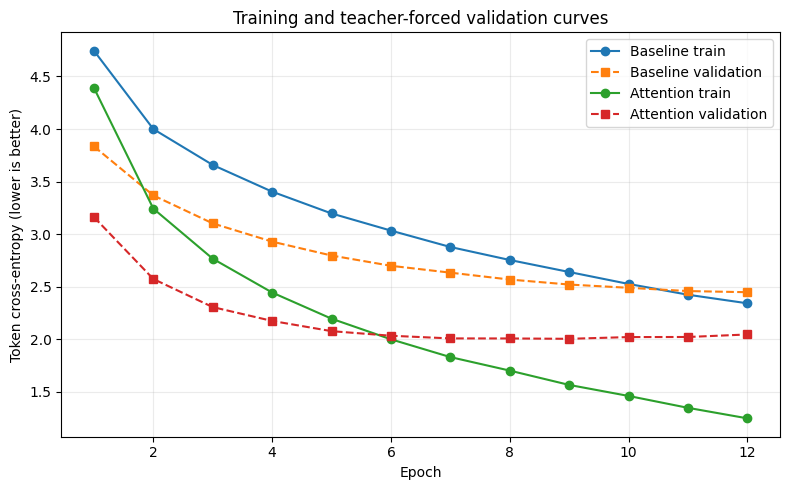

In [5]:
def run_epoch(model,loader,optimizer=None,teacher_forcing_ratio=0.5,max_batches=None):
    training=optimizer is not None; model.train(training)
    total_nll=0.0; total_tokens=0
    for bi,(src,lengths,tgt) in enumerate(loader):
        if max_batches is not None and bi>=max_batches: break
        src,lengths,tgt=src.to(device,non_blocking=True),lengths.to(device),tgt.to(device,non_blocking=True)
        if training: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(src,lengths,tgt,teacher_forcing_ratio if training else 1.0)
            gold=tgt[:,1:]
            loss=criterion(logits.reshape(-1,logits.size(-1)),gold.reshape(-1))
            if training:
                loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        n=int(gold.ne(PAD).sum().item()); total_nll+=loss.item()*n; total_tokens+=n
    return total_nll/max(total_tokens,1)

def count_parameters(model): return sum(p.numel() for p in model.parameters() if p.requires_grad)
def train_model(with_attention,epochs=EPOCHS):
    random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model=make_model(with_attention); optimizer=torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)
    history=[]; best_loss=float('inf'); best_state=None; stale=0
    for epoch in range(1,epochs+1):
        start=time.time()
        train_loss=run_epoch(model,train_loader,optimizer,TEACHER_FORCING_RATIO)
        valid_loss=run_epoch(model,valid_loader)
        history.append({'epoch':epoch,'train_loss':train_loss,'valid_loss':valid_loss,'seconds':time.time()-start})
        print(f"{'attention' if with_attention else 'baseline':9s} epoch {epoch:02d}: train CE={train_loss:.4f} | val CE={valid_loss:.4f} | {history[-1]['seconds']:.1f}s")
        if valid_loss<best_loss:
            best_loss=valid_loss; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; stale=0
        else:
            stale+=1
            if stale>=PATIENCE: print('Early stopping: validation loss did not improve.'); break
    model.load_state_dict(best_state); model.to(device)
    return model,history

if RUN_FULL_TRAINING:
    if DATA_MODE!='multi30k': print('WARNING: smoke mode is not a quality evaluation.')
    baseline,baseline_history=train_model(False)
    attention_model,attention_history=train_model(True)
    print('Trainable parameters | baseline:',count_parameters(baseline),'| attention:',count_parameters(attention_model))
    fig,ax=plt.subplots(figsize=(8,5))
    for label,hist in [('Baseline',baseline_history),('Attention',attention_history)]:
        ax.plot([x['epoch'] for x in hist],[x['train_loss'] for x in hist],marker='o',label=f'{label} train')
        ax.plot([x['epoch'] for x in hist],[x['valid_loss'] for x in hist],marker='s',linestyle='--',label=f'{label} validation')
    ax.set(xlabel='Epoch',ylabel='Token cross-entropy (lower is better)',title='Training and teacher-forced validation curves'); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
    training_summary={'config':{'seed':SEED,'data_mode':DATA_MODE,'train_pairs':len(train_pairs),'validation_pairs':len(valid_pairs),'test_pairs':len(test_pairs),'max_train_pairs':MAX_TRAIN_PAIRS,'epochs_limit':EPOCHS,'batch_size':batch_size,'embedding_dim':EMB_DIM,'hidden_dim':HIDDEN_DIM,'lr':LEARNING_RATE,'teacher_forcing':TEACHER_FORCING_RATIO},'baseline_history':baseline_history,'attention_history':attention_history,'parameters':{'baseline':count_parameters(baseline),'attention':count_parameters(attention_model)}}
    (OUTPUT_DIR/'training_summary.json').write_text(json.dumps(training_summary,indent=2))
else:
    print('Training disabled. Set RUN_FULL_TRAINING=True for the required comparison.')

## 4. Greedy decoding and beam search

Beam score is cumulative log probability divided by the course-specified length penalty `((5 + generated_length) / 6) ** alpha`. Each hypothesis owns its own hidden and cell states. Width one is explicitly kept equivalent to greedy decoding, which is the expected invariant for this lab. Beam search can return a different sentence because it retains alternative prefixes whose later conditional probabilities may outweigh the locally best early token.

In [ ]:
def source_tensor(source_text):
    ids=[SOS]+[src_vocab.get(t,UNK) for t in tokenize(source_text)]+[EOS]
    src=torch.tensor(ids,dtype=torch.long,device=device).unsqueeze(0)
    lengths=torch.tensor([len(ids)],dtype=torch.long,device=device)
    return src,lengths

def greedy_translate(model,source_text,max_steps=MAX_DECODE_STEPS,return_attention=True):
    model.eval(); src,lengths=source_tensor(source_text); generated=[]; rows=[]
    with torch.no_grad():
        enc,(hidden,cell)=model.encoder(src,lengths); mask=src.ne(PAD)
        previous=torch.tensor([SOS],device=device)
        for _ in range(max_steps):
            logits,hidden,cell,weights=model.decoder(previous,hidden,cell,enc,mask)
            logits[:,PAD]=-torch.inf; logits[:,SOS]=-torch.inf
            token=int(logits.argmax(-1).item())
            if token==EOS: break
            if token in (PAD,SOS):
                # Special tokens are never emitted as ordinary translation words.
                previous=torch.tensor([token],device=device); continue
            generated.append(tgt_itos.get(token,'<unk>'))
            if return_attention and weights is not None: rows.append(weights[0].detach().cpu())
            previous=torch.tensor([token],device=device)
    matrix=torch.stack(rows) if rows else None
    return generated,matrix

def beam_translate(model,source_text,beam_width=BEAM_WIDTH,max_steps=MAX_DECODE_STEPS,length_alpha=LENGTH_ALPHA):
    if beam_width<1: raise ValueError('beam_width must be >= 1')
    # Required invariant: width-one decoding is greedy decoding.
    if beam_width==1: return greedy_translate(model,source_text,max_steps,return_attention=False)[0]
    model.eval(); src,lengths=source_tensor(source_text)
    with torch.no_grad():
        enc,(h0,c0)=model.encoder(src,lengths); mask=src.ne(PAD)
        # Hypothesis: (tokens including SOS, cumulative log-probability, hidden, cell, ended)
        beams=[([SOS],0.0,h0,c0,False)]
        def rank(hyp):
            toks,logp,_,_,_=hyp
            generated_len=max(1,len(toks)-1)
            penalty=((5.0+generated_len)/6.0)**length_alpha
            return logp/penalty
        for _ in range(max_steps):
            candidates=[]
            for toks,logp,hidden,cell,ended in beams:
                if ended:
                    candidates.append((toks,logp,hidden,cell,True)); continue
                prev=torch.tensor([toks[-1]],device=device)
                logits,next_h,next_c,_=model.decoder(prev,hidden,cell,enc,mask)
                log_probs=torch.log_softmax(logits,dim=-1).squeeze(0)
                # Exclude PAD and SOS from generated candidates.
                log_probs[PAD]=-torch.inf; log_probs[SOS]=-torch.inf
                k=min(beam_width, int(torch.isfinite(log_probs).sum().item()))
                vals,ids=torch.topk(log_probs,k=k)
                for val,idx in zip(vals.tolist(),ids.tolist()):
                    candidates.append((toks+[idx],logp+float(val),next_h.clone(),next_c.clone(),idx==EOS))
            beams=sorted(candidates,key=rank,reverse=True)[:beam_width]
            if beams and all(b[4] for b in beams): break
        best=max(beams,key=rank)
        ids=best[0][1:]
        if EOS in ids: ids=ids[:ids.index(EOS)]
        return [tgt_itos.get(i,'<unk>') for i in ids if i not in (PAD,SOS,EOS)]

# Check width one == greedy on both architectures, using the same decoding limit.
for model in [baseline,attention_model] if RUN_FULL_TRAINING else [baseline]:
    for source,_ in (valid_pairs[:min(3,len(valid_pairs))]):
        g,_=greedy_translate(model,source,max_steps=12)
        b=beam_translate(model,source,beam_width=1,max_steps=12)
        assert g==b,(source,g,b)
print('PASS: beam width 1 matches greedy.')
print('Greedy demo:', ' '.join(greedy_translate(baseline,valid_pairs[0][0])[0]))

## 5. Held-out perplexity and four-row BLEU comparison

Perplexity is computed from teacher-forced reference-token cross-entropy and therefore is identical for greedy and beam rows for a given model. Corpus BLEU is computed on generated translations and can differ by decoding method. The evaluation sample is identical for all four rows; by default the whole retained test split is used. `sacrebleu`'s default English tokenization is used on the already space-separated outputs. Select hyperparameters using validation data, not the test results.

In [ ]:
def corpus_perplexity(model,pairs):
    loader=DataLoader(PairDataset(pairs),batch_size=batch_size,shuffle=False,collate_fn=collate,num_workers=NUM_WORKERS)
    ce=run_epoch(model,loader)
    return math.exp(min(ce,50.0)),ce

def evaluate_generations(model,pairs,method):
    hypotheses=[]; references=[]
    for source,reference in pairs:
        if method=='greedy': tokens,_=greedy_translate(model,source,max_steps=MAX_DECODE_STEPS)
        elif method=='beam': tokens=beam_translate(model,source,beam_width=BEAM_WIDTH,max_steps=MAX_DECODE_STEPS,length_alpha=LENGTH_ALPHA)
        else: raise ValueError("method must be 'greedy' or 'beam'")
        hypotheses.append(' '.join(tokens).strip())
        references.append(' '.join(tokenize(reference)).strip())
    bleu=BLEU().corpus_score(hypotheses,[references]).score
    exact=sum(h==r for h,r in zip(hypotheses,references))/max(1,len(pairs))
    return {'BLEU':float(bleu),'exact_match':float(exact)},hypotheses,references

if RUN_FULL_TRAINING:
    evaluation_pairs=list(test_pairs)
    if TEST_EVAL_LIMIT is not None:
        evaluation_pairs=random.Random(SEED).sample(evaluation_pairs,min(TEST_EVAL_LIMIT,len(evaluation_pairs)))
    results={}; generated={}; refs_by_key={}
    for model_name,model in [('baseline',baseline),('attention',attention_model)]:
        ppl,ce=corpus_perplexity(model,evaluation_pairs)
        for method in ['greedy','beam']:
            scores,hyps,refs=evaluate_generations(model,evaluation_pairs,method)
            results[(model_name,method)]={'perplexity':ppl,'teacher_forced_CE':ce,**scores}
            generated[(model_name,method)]=hyps; refs_by_key[(model_name,method)]=refs
    print('Evaluated test pairs:',len(evaluation_pairs))
    print('| Model | Decoder | Test perplexity ↓ | BLEU ↑ | Exact match |')
    print('|---|---|---:|---:|---:|')
    for key in [('baseline','greedy'),('baseline','beam'),('attention','greedy'),('attention','beam')]:
        r=results[key]; print(f"| {key[0]} | {key[1]} | {r['perplexity']:.3f} | {r['BLEU']:.2f} | {100*r['exact_match']:.2f}% |")
    # Machine-readable results for the submission's reported values.
    serial={f'{m}_{d}':r for (m,d),r in results.items()}
    (OUTPUT_DIR/'evaluation_results.json').write_text(json.dumps({'n_test':len(evaluation_pairs),'results':serial},indent=2))
else:
    print('Enable full training to produce the required four-row metric table.')

## 6. Three examples and failure analysis

The notebook selects a short input, a long input, and an exact-match failure where available. If there is no exact match (unlikely for a nontrivial test set), it selects the lowest-overlap candidate as a failure candidate. Discuss errors in terms of lexical coverage, word order, morphology, sentence length, and possible exposure bias; do not claim attention alone caused an error.

In [ ]:
if RUN_FULL_TRAINING:
    attention_greedy=generated[('attention','greedy')]
    refs=refs_by_key[('attention','greedy')]
    short_i=min(range(len(evaluation_pairs)),key=lambda i:len(tokenize(evaluation_pairs[i][0])))
    long_i=max(range(len(evaluation_pairs)),key=lambda i:len(tokenize(evaluation_pairs[i][0])))
    failed=[i for i,(h,r) in enumerate(zip(attention_greedy,refs)) if h!=r]
    if failed: fail_i=failed[0]
    else:
        # Fallback: candidate with the least token overlap, transparently labelled.
        def overlap(i):
            a=set(attention_greedy[i].split()); b=set(refs[i].split())
            return len(a&b)/max(1,len(b))
        fail_i=min(range(len(evaluation_pairs)),key=overlap)
    selected=[]
    for label,i in [('SHORT',short_i),('LONG',long_i),('FAILURE ANALYSIS',fail_i)]:
        if i not in [j for _,j in selected]: selected.append((label,i))
    for label,i in selected:
        src,ref=evaluation_pairs[i]
        print(f'\n--- {label} | test index {i} ---')
        print('German source:       ',src)
        print('English reference:   ',' '.join(tokenize(ref)))
        for m in ['baseline','attention']:
            for d in ['greedy','beam']:
                print(f'{m:9s}/{d:6s}:',generated[(m,d)][i])
        if label=='FAILURE ANALYSIS':
            print('Diagnostic: exact match =',attention_greedy[i]==refs[i], '| source tokens =',len(tokenize(src)))
else: print('Examples are generated after evaluation completes.')

## 7. Two attention maps and interpretation

Rows are generated English tokens; columns are German source tokens, including `<sos>` and `<eos>`. Each row should sum to one. Strong attention weights show which encoder representations receive higher weight at a decoding step; they are **not proof of causal explanation or one-to-one word alignment**. Unlike a tweet classifier's single sequence-level attention calculation, this decoder recomputes attention at every output token.

In [ ]:
def plot_attention(model,source_text,title=None):
    tokens,matrix=greedy_translate(model,source_text,max_steps=MAX_DECODE_STEPS,return_attention=True)
    if matrix is None or len(tokens)==0:
        print('No generated tokens/attention weights for:',source_text); return
    source_tokens=['<sos>']+tokenize(source_text)+['<eos>']
    # Attention is recorded only for ordinary generated tokens, matching these rows.
    mat=matrix[:len(tokens),:len(source_tokens)].numpy()
    fig,ax=plt.subplots(figsize=(max(7,len(source_tokens)*0.55),max(3.5,len(tokens)*0.42)))
    im=ax.imshow(mat,aspect='auto',vmin=0,vmax=1,cmap='Blues')
    ax.set_xticks(range(len(source_tokens))); ax.set_xticklabels(source_tokens,rotation=55,ha='right')
    ax.set_yticks(range(len(tokens))); ax.set_yticklabels(tokens)
    ax.set_xlabel('German source position'); ax.set_ylabel('Generated English token')
    ax.set_title(title or f'Attention map: {source_text}')
    fig.colorbar(im,ax=ax,label='Attention weight'); fig.tight_layout(); plt.show()
    print('Source:',source_text,'| generated:', ' '.join(tokens))
    print('Maximum row-sum error:',float(np.abs(mat.sum(axis=1)-1).max()))

if RUN_FULL_TRAINING:
    # Prefer one exact match and one failure; otherwise use the chosen diagnostic indices.
    success=[i for i,(h,r) in enumerate(zip(attention_greedy,refs)) if h==r]
    fail=[i for i,(h,r) in enumerate(zip(attention_greedy,refs)) if h!=r]
    success_i=success[0] if success else short_i
    failure_i=fail[0] if fail else fail_i
    print('SUCCESS/closest example (exact match available:',bool(success),')')
    plot_attention(attention_model,evaluation_pairs[success_i][0],'Attention map — successful/closest example')
    print('FAILURE example (exact match failure available:',bool(fail),')')
    plot_attention(attention_model,evaluation_pairs[failure_i][0],'Attention map — failure example')
else: print('Attention maps are generated after full training and evaluation.')

## 8. Exercise answers (1, 4, 5, 6)

### Exercise 1 — tensor shapes and teacher forcing

For batch size `B`, padded source length `S`, target length `T` including SOS, hidden width `H`, and target vocabulary size `V`: encoder outputs `(B,S,H)`; final hidden and cell `(1,B,H)`; the top decoder hidden/query `(B,H)`; raw attention scores `(B,S)`; normalized weights `(B,S)`; context `(B,H)`; and training logits `(B,T-1,V)`. The target token at position `t` is the label being predicted, so supplying it as the input for the same step leaks the answer. The input is the previous token (gold previous token under teacher forcing, or previous model prediction otherwise). Source-padding masking is distinct from ignoring target PAD positions in the loss.

### Exercise 4 — beam search

Beam search retains multiple partial hypotheses and sums token log probabilities, using `((5 + generated_length)/6)^alpha` as the length penalty. Every hypothesis must carry its own hidden and cell states. Width one matches greedy decoding by construction and is checked above. Wider beams may differ from greedy because a locally weaker first token can lead to a higher-probability complete sequence after later context; length normalization can also change the ranking of completed sequences.

### Exercise 5 — perplexity, BLEU, and evidence

Use the four-row table printed above. Perplexity is the exponentiated teacher-forced test cross-entropy and is independent of whether greedy or beam decoding is used. BLEU evaluates generated sequences, so it can change with decoding. Lower perplexity need not imply higher BLEU: token likelihood rewards calibrated probability on reference prefixes, while BLEU uses clipped n-gram overlap and is sensitive to word order, length, tokenization, and reference phrasing. State whether attention helped only after examining the actual held-out results and validation curves. If differences are small or inconsistent, report that evidence as inconclusive rather than claiming a win. If this is smoke/limited-data mode, do not draw quality conclusions.

### Exercise 6 — attention interpretation and limitations

Use the two maps above. For a noun and another generated token, identify the largest source weights and compare whether they fall near plausible German content words. Attention is recalculated for each decoder token, unlike a tweet classifier that may calculate one attention distribution for a single sequence-level decision. The map is a learned weighting over contextual encoder states, not a guaranteed word alignment or causal explanation; bidirectional? **This implementation uses a unidirectional LSTM**, so each encoder state is contextualized by the preceding source prefix. Diffuse or unexpected weights can reflect representation sharing, reordering, rare words, or model error. Ground the final interpretation in your actual plotted examples rather than inventing observations.